# BCI inefficiency

Hypothesis:
> Resting or pre-trial `alpha`/`mu` power predicts which subjects decode well.

## Datasets

- PhysioNet EEG Motor Movement/Imagery (EEGBCI):
Motor execution and imagery, fists/feet.
Used in notebook 06; large subject pool; both executed and imagined runs

- Cho2017:
Left/right hand imagery.
Many subjects for studying who can and cannot use MI

- Lee2019_MI (OpenBMI):
Left/right hand imagery.
Two sessions; large and recent; big download

Loader MOABB:
https://moabb.neurotechx.com/docs/dataset_summary.html

## Jupyter Server

```sh
apt install python3-full tmux
python3 -m venv .venv 
```

Jupyter daemon:
```sh
tmux new -s bci
# detach: ctrl-b + d
# attach: tmux attach-session -t bci
# sessions: tmux ls

. .venv/bin/activate

pip install notebook
jupyter notebook
# detach: ctrl-b + d
```

Get link with token:
```sh
. .venv/bin/activate
jupyter server list
```


## Project requirements

https://brainu.notion.site/ROBT613-Midterm-Project-Team-fb4daeb28e9182ec9f1b81073551bf6c

Every project must contain the following seven stages, each with at least one figure or table as evidence.

1. **Data audit.** Report subjects, sessions, runs, channels, sampling rate, units, reference, event codes and trial counts per class. Plot raw data and the sensor layout.
2. **Signal inspection.** Show the PSD before and after filtering, and justify filter type, cut-offs and any resampling (notebook 03).
3. **Artifact handling.** Apply at least one method from notebook 04 and show what it removed. Report how many channels, components or epochs were rejected, and why (notebook 05).
4. **Neurophysiological check.** Before decoding, show that the expected signal exists: the P300 in target-minus-non-target ERPs, or mu/beta desynchronization in band power over C3/C4.
5. **Features and classifier.** Build features and a classifier from the scope table inside one scikit-learn `Pipeline`, so that scaling and selection are fitted on training folds only.
6. **Honest evaluation.**
    - Split by run, session or subject with `GroupKFold` or leave-one-group-out, never by random epochs.
    - Report ROC AUC or balanced accuracy as mean ± SD across folds and per subject.
    - Estimate chance level with a permutation test or the binomial limit for your trial count.
    - Tune hyperparameters with nested CV or a held-out validation group.
7. **Hypothesis test.** Run your controlled comparison, changing one factor at a time, and test whether the difference exceeds fold-to-fold variability (for example, a paired Wilcoxon test across subjects).

**Reproducibility.** One notebook runs top to bottom on a fresh Colab CPU runtime. Pin package versions, set random seeds, and list the subject IDs used. Put shared code in functions rather than copied cells.


## MNE-Python

MNE-Python is an open-source Python package for data input/output, preprocessing, exploring, visualizing, and analyzing human neurophysiological data such as EEG.

In [120]:
%pip install mne

Note: you may need to restart the kernel to use updated packages.


In [121]:
import mne
print("mne:", mne.__version__) # 1.13.2

mne: 1.13.2


#### EEGBCI

[/physionet-docs](https://physionet.org/content/eegmmidb/1.0.0/)

The EEG Motor Movement/Imagery Dataset provides 64-channel electroencephalography recordings collected with the BCI2000 system during real and imagined motor tasks. Participants completed 14 experimental runs, including two one-minute baseline recordings with eyes open and eyes closed, followed by three repetitions of four two-minute task conditions. ... EEG signals were recorded according to the international 10-10 electrode placement system at a sampling rate of 160 Hz and are provided in EDF+ format with accompanying annotation channels. Event labels identify rest periods and task onsets using three codes: T0 for rest, T1 for left-fist or both-fists movement/imagery depending on the run type, and T2 for right-fist or both-feet movement/imagery.

[/mne-docs](https://mne.tools/stable/generated/mne.datasets.eegbci.load_data.html)

| run | task |
| --- | --- |
| 1 | Baseline, eyes open |
| 2 | Baseline, eyes closed |
| 3, 7, 11 | Motor execution: left vs right hand |
| 4, 8, 12 | Motor imagery: left vs right hand |
| 5, 9, 13 | Motor execution: hands vs feet |
| 6, 10, 14 | Motor imagery: hands vs feet |



In [122]:
%pip install pooch

Note: you may need to restart the kernel to use updated packages.


In [123]:
mne.set_config("MNE_DATASETS_EEGBCI_PATH", None)
mne.set_config("MNE_DATASETS_GIGADB_PATH", None)
print(mne.get_config())

{'MNE_DATA': '/home/john/mne_data'}


/tmp/ipykernel_179330/1391602920.py:2: RuntimeWarning: Setting non-standard config type: "MNE_DATASETS_GIGADB_PATH"
  mne.set_config("MNE_DATASETS_GIGADB_PATH", None)


In [124]:
import mne
from mne.datasets import eegbci

files = eegbci.load_data(
    subjects=[1, 2], # list(range(1, 110))
    runs=[6, 10, 14], # list(range(1, 15))
    # path="./datasets",
    # update_path=False # don't write path to MNE config
)

print(files)
# [Path('datasets/MNE-eegbci-data/files/eegmmidb/1.0.0/...edf'),]

[PosixPath('/home/john/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R06.edf'), PosixPath('/home/john/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R10.edf'), PosixPath('/home/john/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R14.edf'), PosixPath('/home/john/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S002/S002R06.edf'), PosixPath('/home/john/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S002/S002R10.edf'), PosixPath('/home/john/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S002/S002R14.edf')]


## Cho2017

[/MOABB-Cho2017](https://moabb.neurotechx.com/docs/generated/moabb.datasets.Cho2017.html)

BCI experiment for motor imagery movement (MI movement) of the left and right hands with 52 subjects (19 females, mean age ± SD age = 24.8 ± 3.86 years); Each subject took part in the same experiment, and subject ID was denoted and indexed as s1, s2, …, s52. Subjects s20 and s33 were both-handed, and the other 50 subjects were right-handed.

EEG data were collected using 64 Ag/AgCl active electrodes. A 64-channel montage based on the international 10-10 system was used to record the EEG signals with 512 Hz sampling rates. The EEG device used in this experiment was the Biosemi ActiveTwo system. The BCI2000 system 3.0.2 was used to collect EEG data and present instructions (left hand or right hand MI). Furthermore, we recorded EMG as well as EEG simultaneously with the same system and sampling rate to check actual hand movements. Two EMG electrodes were attached to the flexor digitorum profundus and extensor digitorum on each arm.

Metadata:
- Number of subjects: 52
- Channels: 64 (EEG) + 4 (EMG) + 1 (Events)
- Classes: 2 (left, right hand)
- Number of trials per class: 100-120
- Trials lenght: 3s
- Frequency (sampling rate): 512Hz
- Units: V
- Reference: not given explicitly, on preprocessing - CAR
- Sessions: 1
- Runs: 5, but represented as 1 merged
- Total trials: 10520 

---

4 types of hand movement:


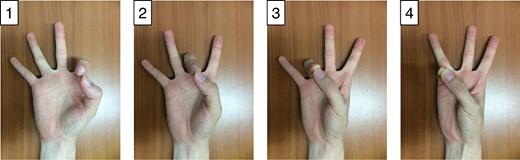

In [125]:
from IPython.display import Image, display

display(Image(filename="assets/hand_movements.jpeg"))


---

[/paper](https://academic.oup.com/gigascience/article/6/7/gix034/3796323)

Experimental procedure:

| Number | Task | Duration (min) |
| --- | --- | --- |
| 1 | Filling in a consent form and questionnaire | 10 |
| 2 | EEG electrode placement | 20 |
| 3 | Acquisition of the 6 types of non-task-related data | 2 |
| 4 | Practicing actual finger movements | 3 |
| 5 | RUN 1 | 6 |
| 6 | Filling out questionnaire | 4 |
| 7 | RUN 2 | 6 |
| 8 | Filling out questionnaire | 4 |
| 9 | RUN 3 | 6 |
| 10 | Filling out questionnaire | 4 |
| 11 | RUN 4 | 6 |
| 12 | Filling out questionnaire | 4 |
| 13 | RUN 5 | 6 |
| 14 | Filling out questionnaire | 4 |
| 15 | Online experiment | 6 |
| 16 | Digitizing 3D coordinates of EEG electrodes | 15 |
| 17 | Removing electrodes and cleaning laboratory | 20 |
| **Sum** | | **126** |

---

Data:
```json
{
subject1: {
    session1: {
        run1: trials, 
        run2: trials, 
        ...,
    },
    session2: {run1, run2, ...,},
    ...
},
subject2: { ... }
}
```

Merged runs:
```json
Left:
[Trial 1][Trial 2][Trial 3] ... [Trial 100]
Right:
[Trial 1][Trial 2][Trial 3] ... [Trial 100]
->
[All Left trials][500 zeros][All Right trials]
```

The whole signal is not continuous.

We will work with each separate trial, which are called Epochs. 

----



#### Download Cho2017

We will load Cho2017 dataset using Mother of All BCI Benchmarks (MOABB).

Install MOABB library:

In [126]:
%pip install moabb

Note: you may need to restart the kernel to use updated packages.


Download Cho2017 dataset:

In [127]:
import moabb
from moabb.datasets import Cho2017

dataset = Cho2017()

# dataset.download() # downloads from nemar.org, please uncomment to donwload

print(dataset.subject_list) # list(range(1, 53))

# files = dataset.data_path(subject=1) # downloads from s3
# print(files)

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52]


Check 1 subject:

In [128]:
data = dataset.get_data(subjects=[1, 2, 3]) 
# data = {"subject_id": {"session_id": {"run_id": run}}}

print(data.keys()) # dict_keys([1, 2, 3])
print(data[1].keys()) # dict_keys(['0']) # 1 session
print(data[1]["0"].keys()) # dict_keys(['0']) # 5 combined runs

raw = data[3]["0"]["0"]

print(raw) # <RawArray | 69 x 717300 (1401.0 s), ~377.7 MiB, data loaded>
print(raw.get_data().shape) # (69, 717300)
print(raw.info["sfreq"]) # 512Hz

for name, channel_type in zip(raw.ch_names, raw.get_channel_types()):
    print(name, channel_type) # eeg, emg, stim

/home/john/Git/BCI_Midterm_Project/.venv/lib/python3.11/site-packages/moabb/datasets/gigadb.py:316: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
Trials demeaned and stacked with zero buffer to create continuous data -- edge effects present
/home/john/Git/BCI_Midterm_Project/.venv/lib/python3.11/site-packages/moabb/datasets/gigadb.py:316: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
Trials demeaned and stacked with zero buffer to create continuous data -- edge effects present
/home/john/Git/BCI_Midterm_Project/.venv/lib/python3.11/site-packages/moabb/datasets/gigadb.py:316: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")


dict_keys([1, 2, 3])
dict_keys(['0'])
dict_keys(['0'])
<RawArray | 69 x 717300 (1401.0 s), ~377.7 MiB, data loaded>
(69, 717300)
512.0
Fp1 eeg
AF7 eeg
AF3 eeg
F1 eeg
F3 eeg
F5 eeg
F7 eeg
FT7 eeg
FC5 eeg
FC3 eeg
FC1 eeg
C1 eeg
C3 eeg
C5 eeg
T7 eeg
TP7 eeg
CP5 eeg
CP3 eeg
CP1 eeg
P1 eeg
P3 eeg
P5 eeg
P7 eeg
P9 eeg
PO7 eeg
PO3 eeg
O1 eeg
Iz eeg
Oz eeg
POz eeg
Pz eeg
CPz eeg
Fpz eeg
Fp2 eeg
AF8 eeg
AF4 eeg
AFz eeg
Fz eeg
F2 eeg
F4 eeg
F6 eeg
F8 eeg
FT8 eeg
FC6 eeg
FC4 eeg
FC2 eeg
FCz eeg
Cz eeg
C2 eeg
C4 eeg
C6 eeg
T8 eeg
TP8 eeg
CP6 eeg
CP4 eeg
CP2 eeg
P2 eeg
P4 eeg
P6 eeg
P8 eeg
P10 eeg
PO8 eeg
PO4 eeg
O2 eeg
EMG1 emg
EMG2 emg
EMG3 emg
EMG4 emg
Stim stim


In [129]:
import mne

# find event onsets by delta(Stim) > 0: [0, 0, 1, 0, 0, 0, 2, 0, 0, 0]
events = mne.find_events(
    raw,
    stim_channel="Stim",
    initial_event=True
)
print(events.shape) # [200, 3]: [[sample_index, previous_value, event_id]...]
print(events[:10])
print(events[95:105])

Finding events on: Stim
200 events found on stim channel Stim
Event IDs: [1 2]
(200, 3)
[[ 1023     0     1]
 [ 4607     0     1]
 [ 8191     0     1]
 [11775     0     1]
 [15359     0     1]
 [18943     0     1]
 [22527     0     1]
 [26111     0     1]
 [29695     0     1]
 [33279     0     1]]
[[341503      0      1]
 [345087      0      1]
 [348671      0      1]
 [352255      0      1]
 [355839      0      1]
 [359923      0      2]
 [363507      0      2]
 [367091      0      2]
 [370675      0      2]
 [374259      0      2]]


Extract epochs from raw:

In [155]:
def get_epochs(raw, events):
    return mne.Epochs(
        raw,
        events,
        event_id={
            "left_hand": 1,
            "right_hand": 2
        },
        tmin=-1.5, # 0,
        tmax=3 - 1 / raw.info["sfreq"], # exclude last sample, 3 - 1/512 = 2.998s
        picks="eeg",
        baseline=None,
        preload=True
    )

epochs = get_epochs(raw, events) # .resample(128)

print(epochs) # 200 events: 100 left, 100 right hand
print(epochs.get_data().shape) # [200, 64, 1536=512*3]

Not setting metadata
200 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 200 events and 2304 original time points ...
0 bad epochs dropped
<Epochs | 200 events (all good), -1.5 – 2.998 s (baseline off), ~225.1 MiB, data loaded,
 'left_hand': 100
 'right_hand': 100>
(200, 64, 2304)


## Time domain 

Left Hand Motor Imagery, C3 EEG channel:

(100, 1, 2304)
Mean: -0.035157511442472845 V
Std: 0.00045003552898354593 V
Min: -0.036707229912281036 V
Max: -0.033780232071876526 V
(2304,)
[-1.5        -1.49804688 -1.49609375 ...  2.99414062  2.99609375
  2.99804688]


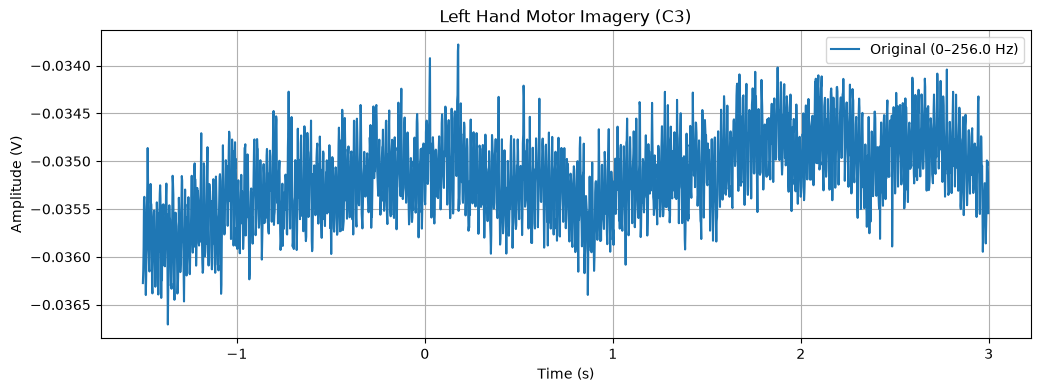

In [156]:
import matplotlib.pyplot as plt


left = epochs["left_hand"]

signal = left.get_data(picks=["C3"])
print(signal.shape) # (100, 1, 1536)

print("Mean:", signal[0].mean(), "V")
print("Std:", signal[0].std(), "V")
print("Min:", signal[0].min(), "V")
print("Max:", signal[0].max(), "V")

signal = signal[0, 0] 
print(signal.shape) # (1536)
time = left.times # [0.0, ..., 2.998]
print(time)

plt.figure(figsize=(12, 4))
plt.plot(time, signal, label=f"Original ({0}–{raw.info['sfreq'] / 2} Hz)")

plt.xlabel("Time (s)")
plt.ylabel("Amplitude (V)")
plt.title("Left Hand Motor Imagery (C3)")
plt.legend()
plt.grid()
plt.show()

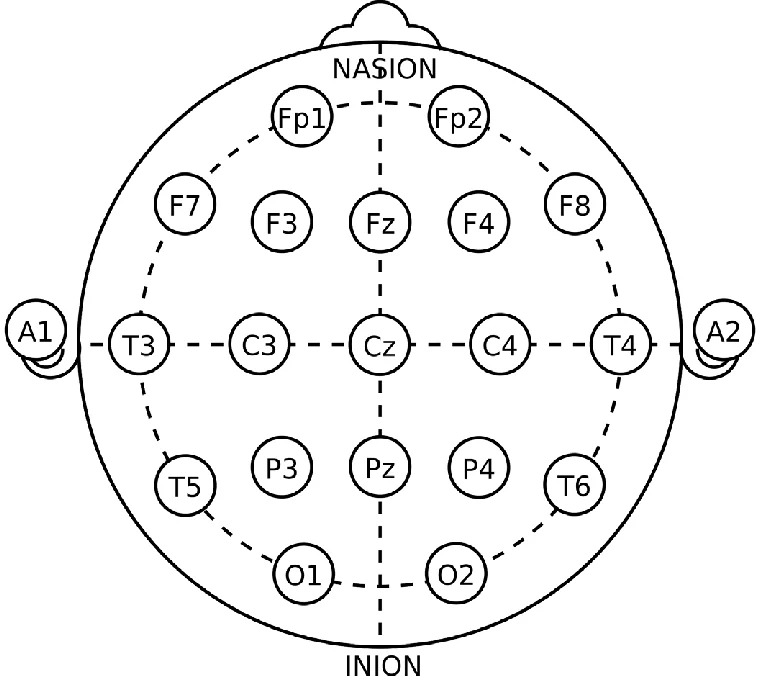

In [157]:
display(Image(
    filename="assets/21_electrodes_of_International_10-20_system_for_EEG.png",
    width=300
))

#### Filter

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 60 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 60.00 Hz
- Upper transition bandwidth: 15.00 Hz (-6 dB cutoff frequency: 67.50 Hz)
- Filter length: 1691 samples (3.303 s)

512.0
Not setting metadata
200 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 200 events and 2304 original time points ...
0 bad epochs dropped


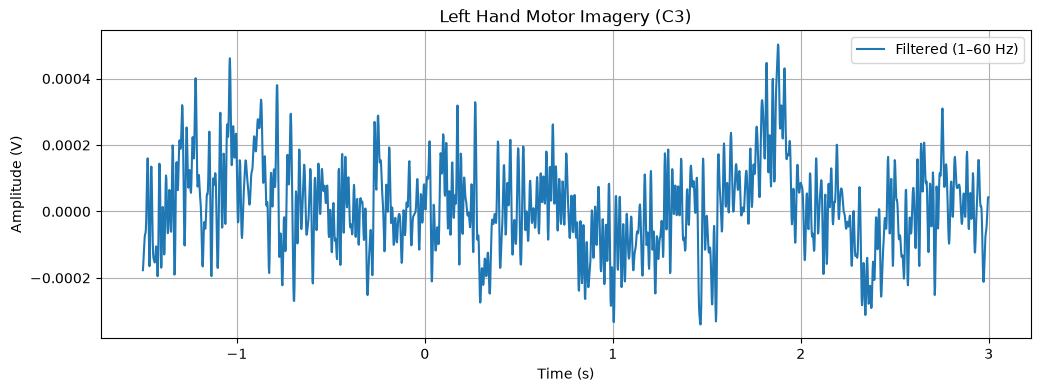

In [ ]:
# Filter raw EEG
filtered = raw.copy()
filtered.set_eeg_reference("average") # Common Average Reference (CAR)
l_freq, h_freq = 1, 60
filtered.filter(l_freq=l_freq, h_freq=h_freq, picks="eeg")
print(filtered.info["sfreq"]) # 512

# Create filtered epochs
filtered_epochs = get_epochs(filtered, events)

# First left-hand trial, C3
before = signal
after = filtered_epochs["left_hand"].get_data(picks=["C3"])[0, 0]

plt.figure(figsize=(12, 4))

# plt.plot(time, before, label="Original")
plt.plot(time, after, label=f"Filtered ({l_freq}–{h_freq} Hz)")

plt.xlabel("Time (s)")
plt.ylabel("Amplitude (V)")
plt.title("Left Hand Motor Imagery (C3)")
plt.legend()
plt.grid()
plt.show()

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


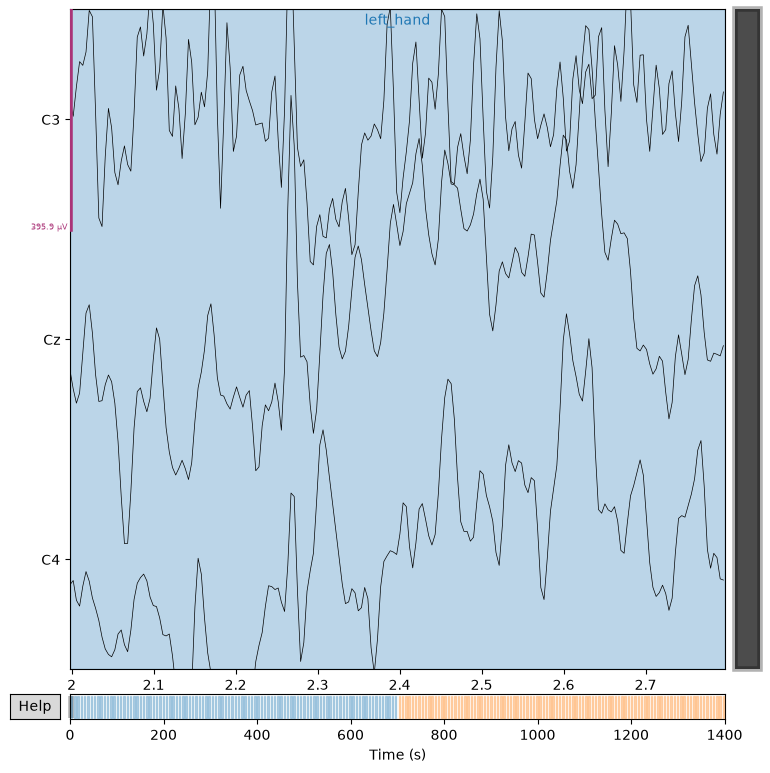

In [159]:
filtered.copy().pick(["C3", "Cz", "C4"]).plot(
    start=events[0, 0] / raw.info["sfreq"],
    duration=0.8,
    scalings="auto",
    remove_dc=False,
    show=False
)
plt.show()

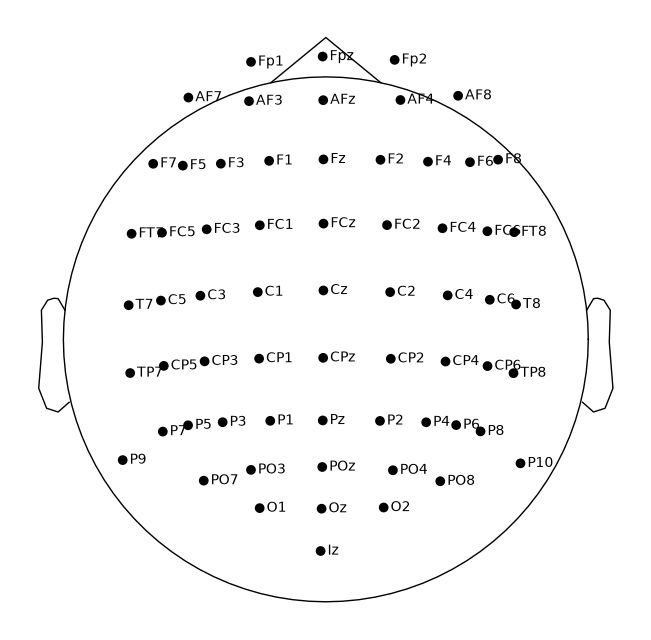

In [160]:
raw.copy().pick("eeg").plot_sensors(
    kind="topomap",
    show_names=True,
    show=False
)
plt.show()

## Frequency domain

#### Power Spectral Density (PSD)

Effective window size : 1.000 (s)
PSD: (200, 2, 35)
Frequencies: (35,)


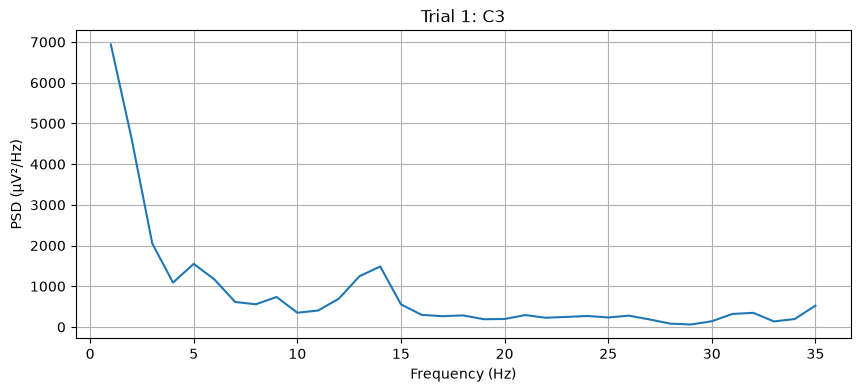

Effective window size : 1.000 (s)


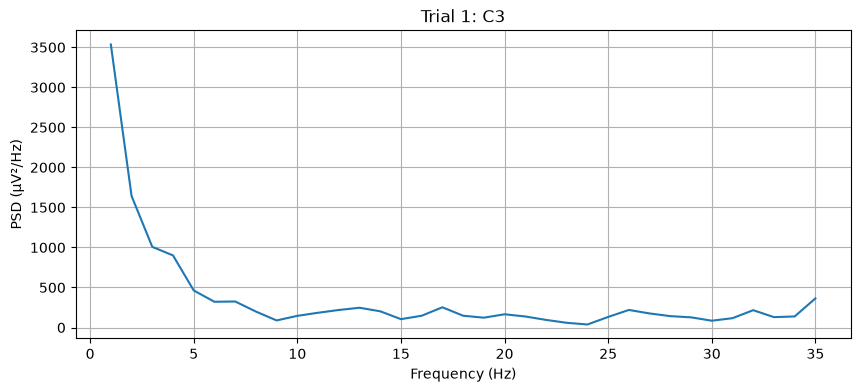

In [176]:
import numpy as np


def get_psd(epochs, fmin=1, fmax=35):
    spectrum = epochs.copy().crop(0, (3 - 1 / raw.info["sfreq"])).compute_psd(
        method="welch",
        picks=["C3", "C4"],
        fmin=fmin,
        fmax=fmax,
        n_fft=512,
        n_per_seg=512,
        n_overlap=256 # 5 windows average
    )
    return spectrum


def visualize_psd(psd, freqs):
    plt.figure(figsize=(10, 4))

    plt.plot(freqs, psd[0, 0, :] * 1e12)

    plt.xlabel("Frequency (Hz)")
    plt.ylabel("PSD (µV²/Hz)")
    plt.title("Trial 1: C3")
    plt.grid()
    plt.show()

# Original
spectrum = get_psd(epochs)
psd, freqs = spectrum.get_data(return_freqs=True)
print("PSD:", psd.shape) # (200, 2, 35)
print("Frequencies:", freqs.shape) # (35,)
visualize_psd(psd, freqs)

# Filtered
filtered_spectrum = get_psd(filtered_epochs)
filtered_psd, filtered_freqs = filtered_spectrum.get_data(return_freqs=True)
visualize_psd(filtered_psd, filtered_freqs)



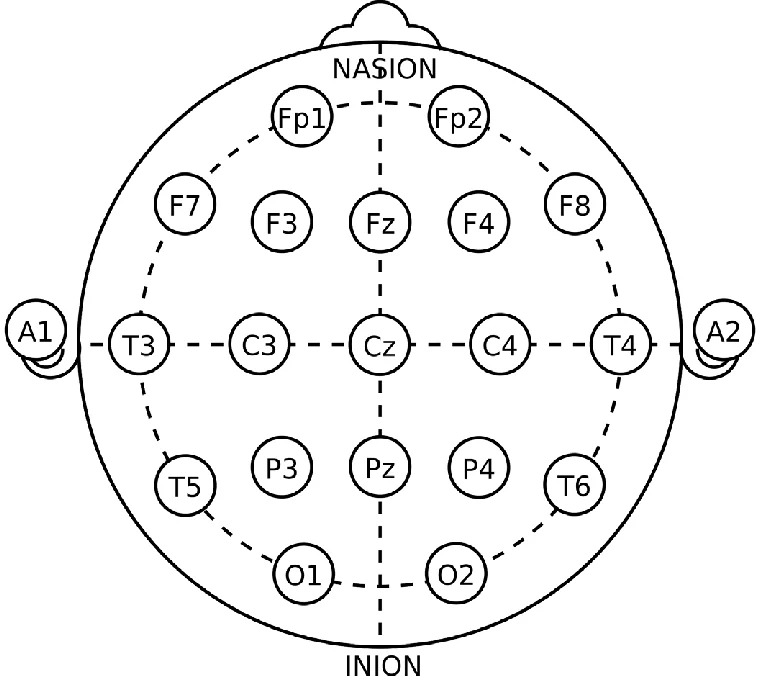

In [167]:
display(Image(
    filename="assets/21_electrodes_of_International_10-20_system_for_EEG.png",
    width=300
))

In [183]:
original_epochs = epochs
epochs = filtered_epochs
psd = filtered_psd
freqs = filtered_freqs

#### Left and right hand motor imagery PSD comparison

On C3 average amplitude of mu waves on right hand trials should be lower, 
and amplitude of mu on C4 on left hand trials should be lower, 
but it is not guaranteed.

Let's take average PSD on C3/C4 separately for left and right hand movements:

(100, 2, 35)
(100, 2, 35)
(35,)
(35,)
C3:
  Left Mu: 2864.12 µV²
  Right Mu: 2552.25 µV²


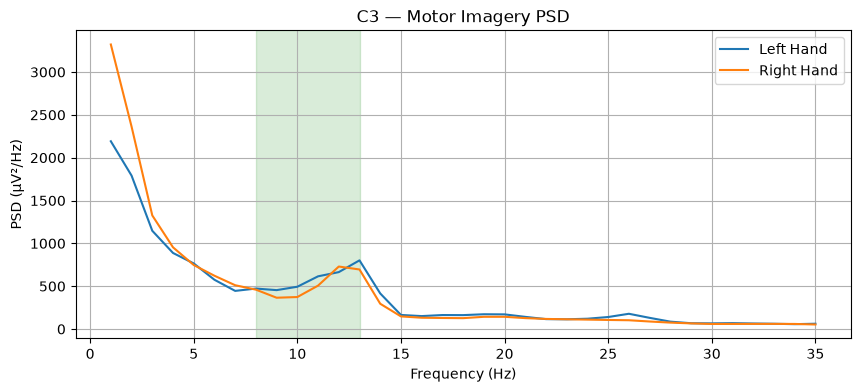

(35,)
(35,)
C4:
  Left Mu: 2632.28 µV²
  Right Mu: 4039.43 µV²


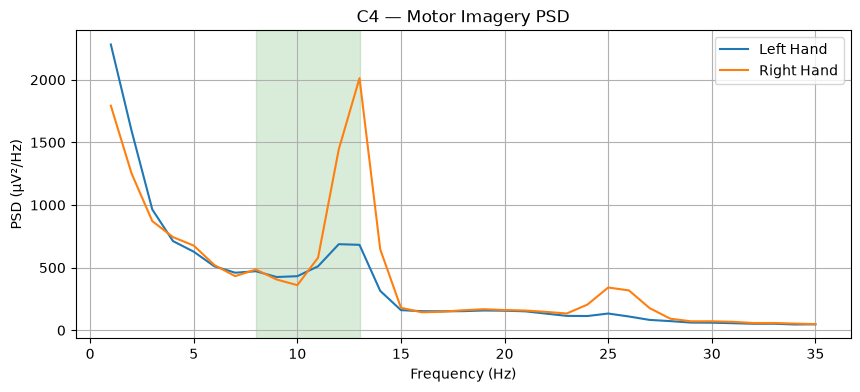

In [184]:
labels = epochs.events[:, 2] # [[sample_index, previous_value, event_id]...]

left_psd = psd[labels == 1] # all trials where label=1 (left)
right_psd = psd[labels == 2]

print(left_psd.shape) # (100, 2, 35)
print(right_psd.shape) # (100, 2, 35)

mu = (freqs >= 8) & (freqs <= 13)

for i, channel in enumerate(["C3", "C4"]):
    # C3 - left, C4 - right

    # e.g. on C3 average amplitude of mu waves on right hand trials should be lower,
    # and amplitude of mu on C4 on left hand trials should be lower
    # but it is not guaranteed
    left_mean = left_psd[:, i, :].mean(axis=0) 
    right_mean = right_psd[:, i, :].mean(axis=0)
    print(left_mean.shape) # (35,) - average C3 frequencies over trials
    print(right_mean.shape) # (35,)

    # average of mu frequencies - scalar
    left_mu = np.trapezoid(left_mean[mu], freqs[mu])
    right_mu = np.trapezoid(right_mean[mu], freqs[mu])

    print(f"{channel}:")
    print(f"  Left Mu: {left_mu * 1e12:.2f} µV²")
    print(f"  Right Mu: {right_mu * 1e12:.2f} µV²")

    # Visualize
    plt.figure(figsize=(10, 4))

    plt.plot(freqs, left_mean * 1e12, label="Left Hand")
    plt.plot(freqs, right_mean * 1e12, label="Right Hand")

    plt.axvspan(8, 13, alpha=0.15, color="green")
    plt.title(f"{channel} — Motor Imagery PSD")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("PSD (µV²/Hz)")
    plt.legend()
    plt.grid()
    plt.show()

#### Event-Related Desyncronization (ERD)

In [187]:
def mu_beta_power(epochs, tmin, tmax):
    spectrum = epochs.copy().crop(tmin, tmax).compute_psd(
        method="welch",
        picks=["C3", "C4"],
        fmin=8,
        fmax=30,
        n_fft=512,
        n_per_seg=512,
        n_overlap=256
    )
    psd, freqs = spectrum.get_data(return_freqs=True)
    return np.trapezoid(psd, freqs, axis=-1)

baseline = mu_beta_power(filtered_epochs, tmin=-1.5, tmax=-0.5)  # (200, 2)
task = mu_beta_power(filtered_epochs, tmin=0.5, tmax=(3 - 1 / raw.info["sfreq"])) # (200, 2)

# 4. Relative power change (%)
erd = (task - baseline) / baseline * 100

labels = filtered_epochs.events[:, 2]

for label, hand in [(1, "Left"), (2, "Right")]:
    values = np.median(erd[labels == label], axis=0)

    print(f"{hand} Hand:")
    print(f"  C3: {values[0]:.2f}%")
    print(f"  C4: {values[1]:.2f}%")

Effective window size : 1.000 (s)
Effective window size : 1.000 (s)
Left Hand:
  C3: -27.64%
  C4: -55.75%
Right Hand:
  C3: -45.72%
  C4: -22.25%
